In [1]:
from flowrec.data.datamodule import AmazonReviewDataConfig, AmazonReviewDataModule
from flowrec.item_representation.content_embeddings import (
    AmazonItemTextBuilder,
    ContentEmbeddingBuilder,
    HashingTextEmbedder,
)
from pathlib import Path

from flowrec.item_representation.content_embeddings import ItemEmbeddingStore, HFTextEmbedder
from flowrec.item_representation.semantic_id.rqvae import (
    RQVAEConfig,
    RQVAETrainConfig)
from flowrec.item_representation.semantic_id.rqvae_tokenizer import  RQVAEItemTokenizer, RQVAEItemTokenizerConfig

In [2]:
cfg = AmazonReviewDataConfig(
    reviews_path="../data/raw/dataframe_format/reviews_beauty_2014.parquet",
    metadata_path="../data/raw/dataframe_format/meta_beauty_2014.parquet",
    item_key="asin",

    min_user_interactions=5,
    min_item_interactions=5,

    split_strategy="leave_one_out",
    deduplicate_consecutive = False,
    filter_cold_items_after_split = False,

    max_history_len=20,
    batch_size=256,
    eval_batch_size=512,
)

dm = AmazonReviewDataModule(cfg)
dm.setup()

print(dm.summary())

{'num_users': 22363, 'num_items': 12101, 'num_train_examples': 131413, 'num_val_examples': 22363, 'num_test_examples': 22363, 'num_interactions': 198502, 'mean_history_len': 6.695047661222103, 'mean_train_history_len': 6.701551596873977, 'mean_val_history_len': 6.19872110181997, 'mean_test_history_len': 7.153154764566471, 'post_filter_cold_items': False, 'cold_item_reference': 'observed', 'num_items_before_cold_filter': 12101, 'num_cold_items_removed': 0, 'num_train_examples_dropped_cold': 0, 'num_val_examples_dropped_cold': 0, 'num_test_examples_dropped_cold': 0, 'num_train_history_items_removed_cold': 0, 'num_val_history_items_removed_cold': 0, 'num_test_history_items_removed_cold': 0, 'split_strategy': 'leave_one_out', 'global_val_cutoff': None, 'global_test_cutoff': None, 'sid_len': None, 'item_vocab_size': 12102, 'post_split_filter': {'enabled': False, 'train_item_source': 'observed', 'min_history_len': 1, 'num_items_before': 12101, 'num_items_after': 12101, 'num_items_removed': 0

In [3]:
dm.item2id

{'B004756YJA': 1,
 'B004ZT0SSG': 2,
 'B0020YLEYK': 3,
 'B002WLWX82': 4,
 '7806397051': 5,
 'B0009P4PZC': 6,
 'B009HULFLW': 7,
 'B00BZ1QN2C': 8,
 'B00G2TQNZ4': 9,
 'B00812ZWOS': 10,
 'B0000YUX4O': 11,
 'B003H8180I': 12,
 'B00538TSMU': 13,
 'B002S8TOYU': 14,
 'B001MP471K': 15,
 'B00011JI88': 16,
 'B00C1F13CQ': 17,
 'B003ATNYJC': 18,
 'B003ZS6ONQ': 19,
 'B0030HKJ8I': 20,
 'B002PMLGOU': 21,
 'B00027D8IC': 22,
 'B00BN1MPPS': 23,
 'B004Z40048': 24,
 'B009PZVOF6': 25,
 'B008LQX8J0': 26,
 'B009DDGHFC': 27,
 'B007EHWDTS': 28,
 'B00DQ2ILQY': 29,
 'B002BGDLDO': 30,
 'B003VWZCMK': 31,
 'B00DAYGJVW': 32,
 'B0048O2R1E': 33,
 'B004H53CY0': 34,
 'B0035LCW0M': 35,
 'B002OVV7F0': 36,
 'B00021KD2C': 37,
 'B003UHKJ5G': 38,
 'B0068Y6CA4': 39,
 'B0022PG9G0': 40,
 'B008B7QY0E': 41,
 'B003H2MR2W': 42,
 'B007RX3AFA': 43,
 'B0068Z7MT8': 44,
 'B003UYZ9XQ': 45,
 'B007Q22HMY': 46,
 'B0035LT8WM': 47,
 'B004S3M2V0': 48,
 'B00A6SONHM': 49,
 'B005P0QN56': 50,
 'B0067F8BBM': 51,
 'B003HFSZ3Y': 52,
 'B003F2T0M4': 53,
 '

In [4]:
dm.id2item

['<PAD>',
 'B004756YJA',
 'B004ZT0SSG',
 'B0020YLEYK',
 'B002WLWX82',
 '7806397051',
 'B0009P4PZC',
 'B009HULFLW',
 'B00BZ1QN2C',
 'B00G2TQNZ4',
 'B00812ZWOS',
 'B0000YUX4O',
 'B003H8180I',
 'B00538TSMU',
 'B002S8TOYU',
 'B001MP471K',
 'B00011JI88',
 'B00C1F13CQ',
 'B003ATNYJC',
 'B003ZS6ONQ',
 'B0030HKJ8I',
 'B002PMLGOU',
 'B00027D8IC',
 'B00BN1MPPS',
 'B004Z40048',
 'B009PZVOF6',
 'B008LQX8J0',
 'B009DDGHFC',
 'B007EHWDTS',
 'B00DQ2ILQY',
 'B002BGDLDO',
 'B003VWZCMK',
 'B00DAYGJVW',
 'B0048O2R1E',
 'B004H53CY0',
 'B0035LCW0M',
 'B002OVV7F0',
 'B00021KD2C',
 'B003UHKJ5G',
 'B0068Y6CA4',
 'B0022PG9G0',
 'B008B7QY0E',
 'B003H2MR2W',
 'B007RX3AFA',
 'B0068Z7MT8',
 'B003UYZ9XQ',
 'B007Q22HMY',
 'B0035LT8WM',
 'B004S3M2V0',
 'B00A6SONHM',
 'B005P0QN56',
 'B0067F8BBM',
 'B003HFSZ3Y',
 'B003F2T0M4',
 'B008JWW914',
 'B000NJE40K',
 'B006LXPRBW',
 'B001W2K51O',
 'B0049WJA9C',
 'B000VBDWQC',
 'B0001Y74XG',
 'B001U1HI5I',
 'B0047ETODO',
 'B003CGTKUK',
 'B004MOU4C4',
 'B001H54SQ4',
 'B000EODF9K',


In [5]:
len(dm.item2id)

12101

In [6]:
len(dm.id2item)

12102

In [7]:
metadata_path = Path("../data/raw/dataframe_format/meta_beauty_2014.parquet")
output_path = Path("../artifacts/item_embeddings/beauty_content_embeddings.pt")
output_path.parent.mkdir(parents=True, exist_ok=True)

In [8]:
text_builder = AmazonItemTextBuilder(
    include_title=True,
    include_categories=True,
    include_features=True,
    include_description=True,
    include_details=True,
    include_price=False,
    max_chars=4096,
)

embedder = HFTextEmbedder(
    model_name="sentence-transformers/all-MiniLM-L6-v2",
    device="cpu",
    max_length=256,
    normalize=False,
    pooling="masked_mean",
    show_progress=True,
)

builder = ContentEmbeddingBuilder(
    text_builder=text_builder,
    embedder=embedder,
    item_key="parent_asin",
)

result = builder.build_from_metadata(
    metadata_path=metadata_path,
    batch_size=512,
    allowed_item_ids=list(dm.item2id.keys()),
)

result.store.save(output_path)

print("Saved embeddings to:", output_path)
print("Number of items:", len(result.store.item_ids))
print("Embedding shape:", result.store.embeddings.shape)

/opt/anaconda3/envs/synth/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 22372.52it/s]
Embedding items with sentence-transformers/all-MiniLM-L6-v2: 100%|██████████| 24/24 [02:29<00:00,  6.24s/it]

Saved embeddings to: ../artifacts/item_embeddings/beauty_content_embeddings.pt
Number of items: 12101
Embedding shape: torch.Size([12101, 384])


In [9]:
embeddings_path = Path("../artifacts/item_embeddings/beauty_content_embeddings.pt")
output_dir = Path("../artifacts/tokenizers/rqvae_beauty")
output_dir.mkdir(parents=True, exist_ok=True)

In [10]:
embedding_store = ItemEmbeddingStore.load(embeddings_path)

item_ids = embedding_store.item_ids
embeddings = embedding_store.embeddings

print("Number of items:", len(item_ids))
print("Embedding shape:", embeddings.shape)

Number of items: 12101
Embedding shape: torch.Size([12101, 384])


In [11]:
rqvae_cfg = RQVAEConfig(
    input_dim=embeddings.shape[1],
    latent_dim=32,
    hidden_dims=(512, 256, 128),
    num_codebooks=3,
    codebook_size=256,
    commitment_weight=0.25,
    dropout=0.0,
    use_batch_norm=False,
)

train_cfg = RQVAETrainConfig(
    epochs=20,
    batch_size=1024,
    learning_rate=1e-3,
    weight_decay=0.0,
    val_ratio=0.05,
    seed=42,
    gradient_clip_norm=1.0,
    device="cpu", 
    codebook_init = "kmeans"
)

tokenizer_cfg = RQVAEItemTokenizerConfig(
    rqvae=rqvae_cfg,
    train=train_cfg,

    # Recommended for text embeddings.
    normalize="none",

    # Important for TIGER-style flat token vocabulary:
    # code_l -> code_l + l * codebook_size
    level_offset_tokens=False,

    # Resolve duplicate semantic IDs by appending a suffix token.
    collision_policy="random_append",

    encode_batch_size=4096,
)


In [12]:
tokenizer = RQVAEItemTokenizer(tokenizer_cfg)

tokenizer.fit(
    embeddings=embeddings,
    item_ids=item_ids,
)

Initializing RQ-VAE codebooks with k-means...


rqvae epoch 1/20: 100%|██████████| 12/12 [00:00<00:00, 23.67it/s, loss=0.0166, recon_loss=0.0166, vq_loss=1.6e-5, dead_codes_l0=132, dead_codes_l1=22, dead_codes_l2=32]


{"epoch": 1, "step": 12, "train_dead_codes_l0": 152.665275, "train_dead_codes_l1": 15.497564, "train_dead_codes_l2": 14.897704, "train_loss": 0.018666, "train_recon_loss": 0.018643, "train_vq_loss": 2.3e-05, "val_loss": 0.016573, "val_recon_loss": 0.01656, "val_vq_loss": 1.3e-05}


rqvae epoch 2/20: 100%|██████████| 12/12 [00:00<00:00, 23.44it/s, loss=0.0177, recon_loss=0.0175, vq_loss=0.000193, dead_codes_l0=22, dead_codes_l1=12, dead_codes_l2=6]


{"epoch": 2, "step": 24, "train_dead_codes_l0": 61.459986, "train_dead_codes_l1": 14.672234, "train_dead_codes_l2": 13.39318, "train_loss": 0.016782, "train_recon_loss": 0.01675, "train_vq_loss": 3.2e-05, "val_loss": 0.016253, "val_recon_loss": 0.0162, "val_vq_loss": 5.2e-05}


rqvae epoch 3/20: 100%|██████████| 12/12 [00:00<00:00, 24.38it/s, loss=0.017, recon_loss=0.0169, vq_loss=2.1e-5, dead_codes_l0=16, dead_codes_l1=19, dead_codes_l2=19]  


... (31 outputs left out)

rqvae epoch 19/20: 100%|██████████| 12/12 [00:00<00:00, 28.83it/s, loss=0.0132, recon_loss=0.013, vq_loss=0.000169, dead_codes_l0=0, dead_codes_l1=0, dead_codes_l2=1]


{"epoch": 19, "step": 228, "train_dead_codes_l0": 0.0, "train_dead_codes_l1": 0.089074, "train_dead_codes_l2": 0.910926, "train_loss": 0.012845, "train_recon_loss": 0.012674, "train_vq_loss": 0.000172, "val_loss": 0.012711, "val_recon_loss": 0.012537, "val_vq_loss": 0.000174}


rqvae epoch 20/20: 100%|██████████| 12/12 [00:00<00:00, 29.78it/s, loss=0.0131, recon_loss=0.0129, vq_loss=0.000222, dead_codes_l0=0, dead_codes_l1=0, dead_codes_l2=0]


{"epoch": 20, "step": 240, "train_dead_codes_l0": 0.0, "train_dead_codes_l1": 0.0, "train_dead_codes_l2": 0.534447, "train_loss": 0.01274, "train_recon_loss": 0.012554, "train_vq_loss": 0.000186, "val_loss": 0.012638, "val_recon_loss": 0.012448, "val_vq_loss": 0.00019}


In [13]:
print(tokenizer.config.level_offset_tokens)
print(type(tokenizer.config.level_offset_tokens))

False
<class 'bool'>


In [14]:
tokenizer.save(output_dir)

semantic_ids_path = output_dir / "semantic_ids.json"

print("Saved tokenizer to:", output_dir)
print("Saved semantic IDs to:", semantic_ids_path)

Saved tokenizer to: ../artifacts/tokenizers/rqvae_beauty
Saved semantic IDs to: ../artifacts/tokenizers/rqvae_beauty/semantic_ids.json


In [15]:
semantic_id_store = tokenizer.semantic_id_store
semantic_id_mapping = semantic_id_store.to_plain_dict()
semantic_id_mapping

{'7806397051': [133, 233, 57, 102],
 '9759091062': [203, 135, 215, 2],
 '9788072216': [59, 172, 129, 24],
 '9790790961': [200, 157, 225, 74],
 '9790794231': [140, 242, 225, 46],
 'B00004TMFE': [34, 48, 144, 191],
 'B00004TUBL': [236, 125, 55, 85],
 'B00004TUBV': [73, 144, 49, 143],
 'B00004U9V2': [27, 143, 254, 116],
 'B00004U9UY': [34, 139, 138, 91],
 'B000050B6U': [181, 89, 135, 87],
 'B000052WYL': [241, 80, 198, 106],
 'B000052WYN': [110, 37, 212, 143],
 'B000052X9G': [230, 150, 124, 66],
 'B000052WYD': [99, 15, 112, 186],
 'B000052WY7': [241, 8, 82, 185],
 'B000052XIA': [46, 157, 66, 70],
 'B000052XW5': [255, 33, 66, 124],
 'B000052XZP': [245, 30, 66, 45],
 'B000052XYQ': [216, 165, 154, 124],
 'B000052Y5F': [5, 154, 61, 98],
 'B000052Y6Z': [186, 115, 169, 48],
 'B000052Y33': [2, 115, 233, 193],
 'B000052XZX': [19, 77, 72, 246],
 'B000052Y25': [216, 156, 144, 218],
 'B000052YKI': [138, 106, 129, 121],
 'B000052YM8': [252, 80, 198, 61],
 'B000052YJM': [116, 77, 170, 132],
 'B000052YK

In [16]:
len(semantic_id_mapping)

12101

In [17]:
dm.add_semantic_ids(semantic_ids=semantic_id_mapping)

In [18]:
dm.semantic_ids

{'7806397051': [134, 234, 58, 103],
 '9759091062': [204, 136, 216, 3],
 '9788072216': [60, 173, 130, 25],
 '9790790961': [201, 158, 226, 75],
 '9790794231': [141, 243, 226, 47],
 'B00004TMFE': [35, 49, 145, 192],
 'B00004TUBL': [237, 126, 56, 86],
 'B00004TUBV': [74, 145, 50, 144],
 'B00004U9V2': [28, 144, 255, 117],
 'B00004U9UY': [35, 140, 139, 92],
 'B000050B6U': [182, 90, 136, 88],
 'B000052WYL': [242, 81, 199, 107],
 'B000052WYN': [111, 38, 213, 144],
 'B000052X9G': [231, 151, 125, 67],
 'B000052WYD': [100, 16, 113, 187],
 'B000052WY7': [242, 9, 83, 186],
 'B000052XIA': [47, 158, 67, 71],
 'B000052XW5': [256, 34, 67, 125],
 'B000052XZP': [246, 31, 67, 46],
 'B000052XYQ': [217, 166, 155, 125],
 'B000052Y5F': [6, 155, 62, 99],
 'B000052Y6Z': [187, 116, 170, 49],
 'B000052Y33': [3, 116, 234, 194],
 'B000052XZX': [20, 78, 73, 247],
 'B000052Y25': [217, 157, 145, 219],
 'B000052YKI': [139, 107, 130, 122],
 'B000052YM8': [253, 81, 199, 62],
 'B000052YJM': [117, 78, 171, 133],
 'B000052Y

In [19]:
len(dm.semantic_ids)

12101

Items: 12,101
Codebook levels: 4
Pairwise distances computed: 1,000,000 of 73,211,050 possible pairs
Exact semantic-code collisions in computed pairs: 0
Mean / median Hamming distance: 3.975 / 4.000


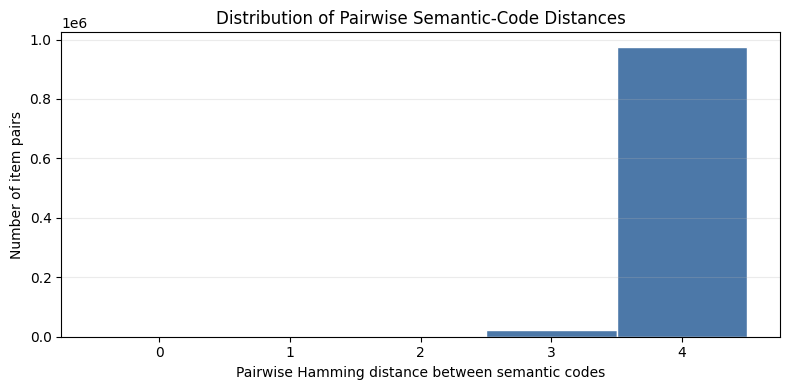

,count,mean,std,min,25%,50%,75%,max
codebook_level,,,,,,,,
0,256.0,47.27,32.374,3.0,23.00,40.0,65.25,206.0
1,256.0,47.27,42.251,1.0,16.75,35.0,66.00,214.0
2,256.0,47.27,51.294,1.0,12.75,27.5,65.00,246.0
3,256.0,47.27,7.337,26.0,43.00,47.0,52.00,68.0


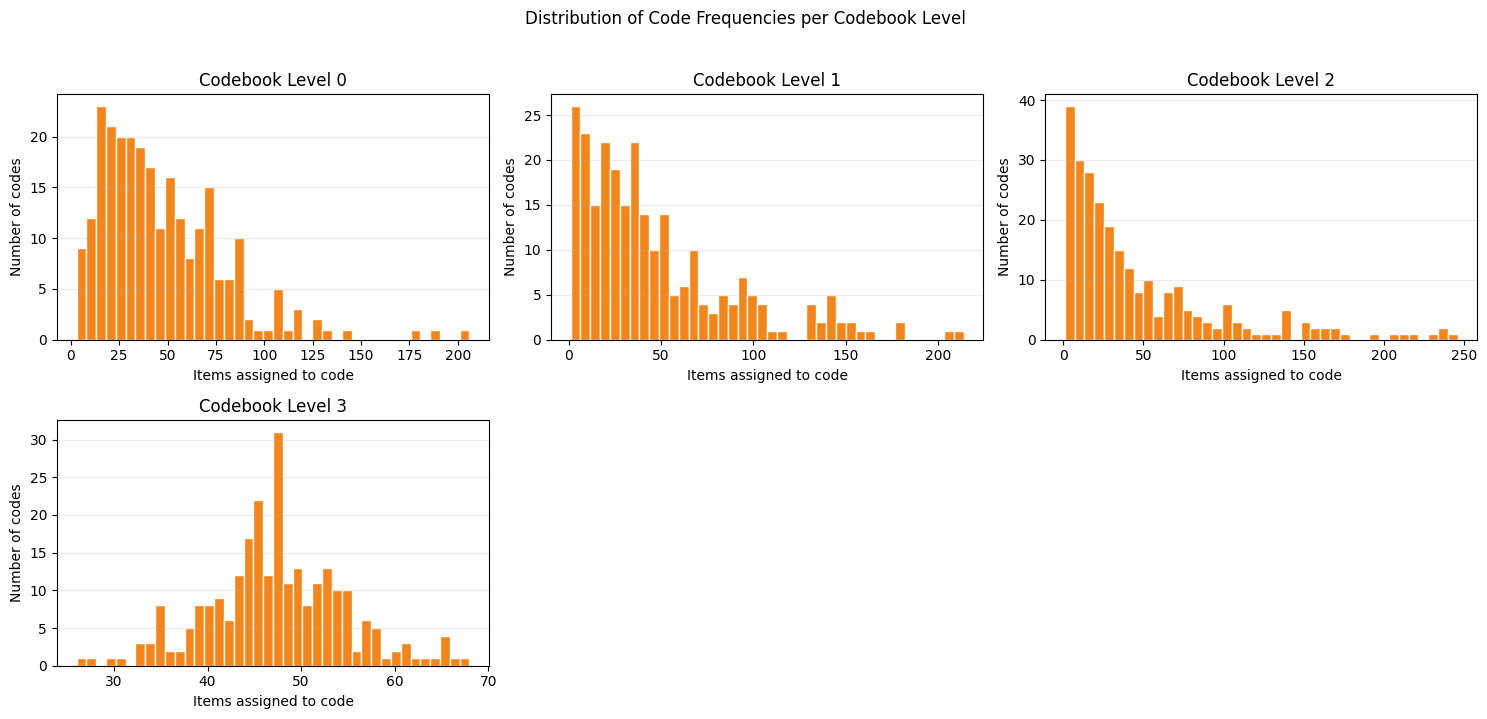

In [20]:
import math
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Semantic-ID diagnostics: pairwise code distances and per-codebook code frequencies.
# For large catalogs, pairwise distances are estimated from sampled item pairs to keep
# the analysis memory-safe.
semantic_codes = np.asarray(
    [semantic_id_mapping[item_id] for item_id in sorted(semantic_id_mapping)],
    dtype=np.int64,
)

if semantic_codes.ndim != 2 or semantic_codes.shape[0] == 0:
    raise ValueError("semantic_id_mapping must contain non-empty, fixed-length code lists.")

num_items, num_codebooks = semantic_codes.shape
max_pair_samples = 1_000_000
rng = np.random.default_rng(42)
num_all_pairs = num_items * (num_items - 1) // 2

if num_all_pairs <= max_pair_samples:
    pair_i, pair_j = np.triu_indices(num_items, k=1)
else:
    pair_i = rng.integers(0, num_items, size=max_pair_samples, endpoint=False)
    pair_j = rng.integers(0, num_items - 1, size=max_pair_samples, endpoint=False)
    pair_j = pair_j + (pair_j >= pair_i)

pairwise_hamming_distances = (semantic_codes[pair_i] != semantic_codes[pair_j]).sum(axis=1)
pairwise_exact_matches = (pairwise_hamming_distances == 0).sum()

print(f"Items: {num_items:,}")
print(f"Codebook levels: {num_codebooks:,}")
print(f"Pairwise distances computed: {len(pairwise_hamming_distances):,} of {num_all_pairs:,} possible pairs")
print(f"Exact semantic-code collisions in computed pairs: {pairwise_exact_matches:,}")
print(
    "Mean / median Hamming distance: "
    f"{pairwise_hamming_distances.mean():.3f} / {np.median(pairwise_hamming_distances):.3f}"
)

fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(num_codebooks + 2) - 0.5
ax.hist(pairwise_hamming_distances, bins=bins, color="#4c78a8", edgecolor="white")
ax.set_xticks(range(num_codebooks + 1))
ax.set_xlabel("Pairwise Hamming distance between semantic codes")
ax.set_ylabel("Number of item pairs")
ax.set_title("Distribution of Pairwise Semantic-Code Distances")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

frequency_rows = []
for level in range(num_codebooks):
    counts = Counter(semantic_codes[:, level].tolist())
    for code, frequency in counts.items():
        frequency_rows.append(
            {
                "codebook_level": level,
                "code": code,
                "frequency": frequency,
                "frequency_share": frequency / num_items,
            }
        )

code_frequency_df = pd.DataFrame(frequency_rows)
display(
    code_frequency_df.groupby("codebook_level")["frequency"]
    .describe()
    .round(3)
)

ncols = min(3, num_codebooks)
nrows = math.ceil(num_codebooks / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.5 * nrows), squeeze=False)

for level, ax in enumerate(axes.ravel()):
    if level >= num_codebooks:
        ax.axis("off")
        continue

    level_freqs = code_frequency_df.loc[
        code_frequency_df["codebook_level"] == level,
        "frequency",
    ]
    ax.hist(level_freqs, bins=40, color="#f58518", edgecolor="white")
    ax.set_title(f"Codebook Level {level}")
    ax.set_xlabel("Items assigned to code")
    ax.set_ylabel("Number of codes")
    ax.grid(axis="y", alpha=0.25)

fig.suptitle("Distribution of Code Frequencies per Codebook Level", y=1.02)
plt.tight_layout()
plt.show()


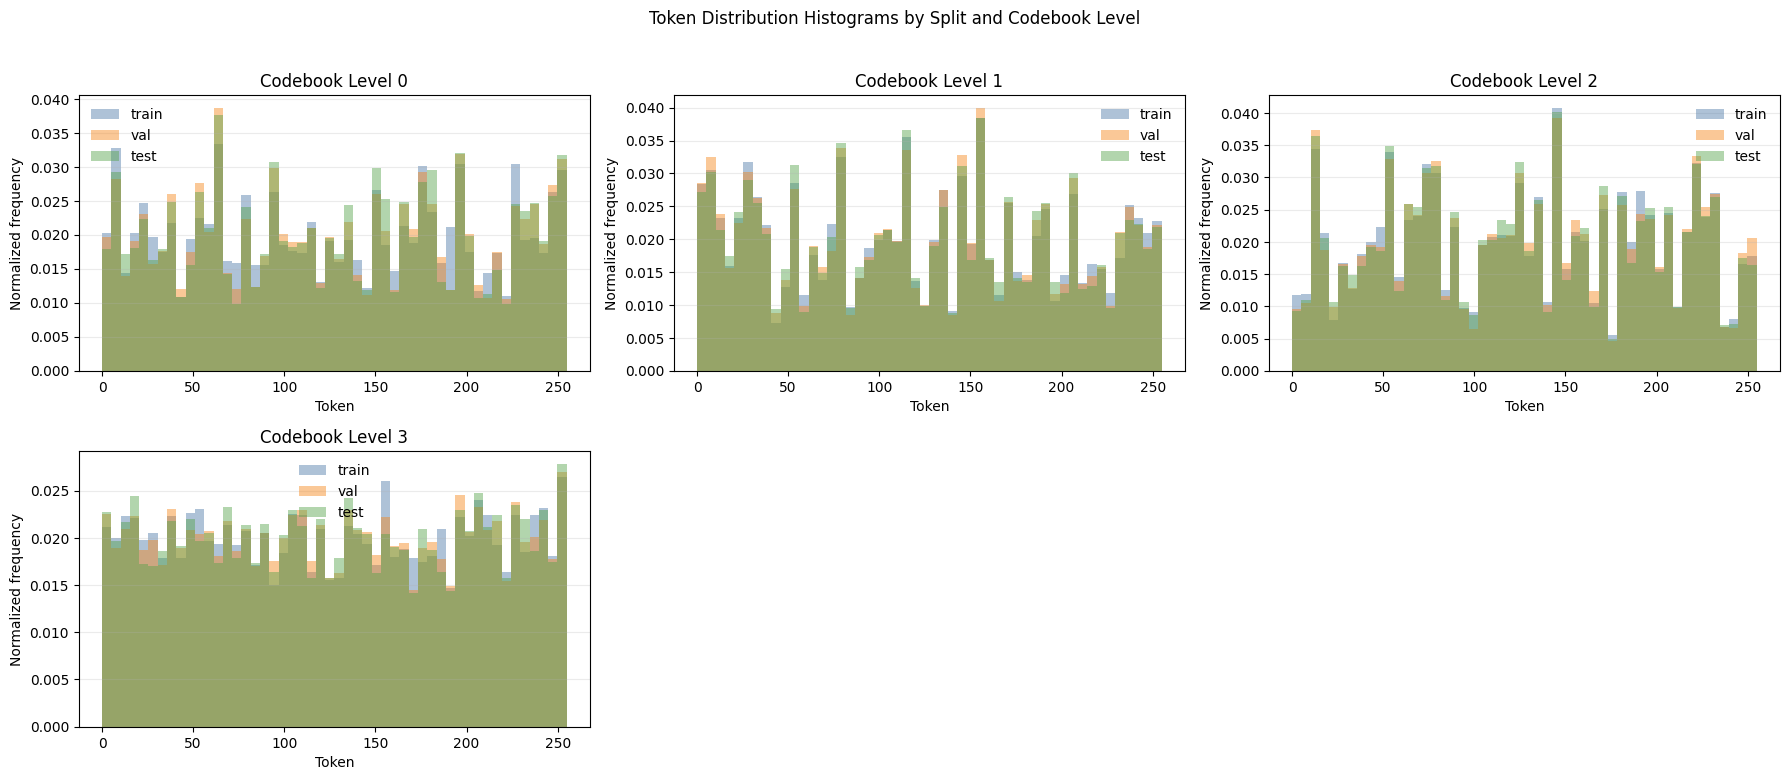

In [21]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

split_datasets = {
    "train": dm.train_dataset,
    "val": dm.val_dataset,
    "test": dm.test_dataset,
}
subset_colors = {
    "train": "#4c78a8",
    "val": "#f58518",
    "test": "#54a24b",
}

if any(dataset is None for dataset in split_datasets.values()):
    raise RuntimeError("Call dm.setup() before plotting split token distributions.")

# dataset.examples is now a DataFrame with a `target_raw_item` column, so we map
# each target item to its semantic-ID codes and explode the per-level tokens.
rows = []
for split_name, dataset in split_datasets.items():
    target_raw_items = dataset.examples["target_raw_item"].astype(str)
    for raw_item in target_raw_items:
        tokens = semantic_id_mapping.get(raw_item)
        if tokens is None:
            continue
        for level, token in enumerate(tokens):
            rows.append(
                {
                    "split": split_name,
                    "codebook_level": level,
                    "token": int(token),
                }
            )

split_token_df = pd.DataFrame(rows)
if split_token_df.empty:
    raise ValueError("No split target items matched semantic_id_mapping.")

num_levels = int(split_token_df["codebook_level"].max()) + 1
ncols = min(3, num_levels)
nrows = int(np.ceil(num_levels / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 3.8 * nrows), squeeze=False)

for level, ax in enumerate(axes.ravel()):
    if level >= num_levels:
        ax.axis("off")
        continue

    level_df = split_token_df[split_token_df["codebook_level"] == level]
    token_min = int(level_df["token"].min())
    token_max = int(level_df["token"].max())


    for split_name in ("train", "val", "test"):
        split_tokens = level_df.loc[level_df["split"] == split_name, "token"].to_numpy()
        if len(split_tokens) == 0:
            continue
        weights = np.ones_like(split_tokens, dtype=float) / len(split_tokens)
        ax.hist(
            split_tokens,
            bins=50,
            weights=weights,
            color=subset_colors[split_name],
            alpha=0.45,
            label=split_name,
            edgecolor="none",
        )

    ax.set_title(f"Codebook Level {level}")
    ax.set_xlabel("Token")
    ax.set_ylabel("Normalized frequency")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(frameon=False)

fig.suptitle("Token Distribution Histograms by Split and Codebook Level", y=1.02)
plt.tight_layout()
plt.show()
